# Functions

## What are functions?

Functions are reusable blocks of code that perform a specific task. They help streamline your code by allowing you to avoid repetition, improve readability, and make maintenance easier.

The general syntax for defining a function is the following:

```python
def function_name(parameter_1, ..., parameter_n):
    """Docstring"""
    <body of the function>
    return value  # Depending on the function
```

In [1]:
# Example 1: one-line docstring, no parameters, no return value
def greet():
    """Print a greeting message."""
    print("Hello, welcome to the class!")

In [2]:
# Example 2: multi-line docstring, parameters, and return value
def calculate_area(radius):
    """
    Calculate the area of a circle given its radius.
    
    Args:
        radius (float): The radius of the circle.
        
    Returns:
        float: The area of the circle, calculated as π * radius^2.
    """
    area = 3.14159 * radius ** 2
    return area

## Data loading and preparation

We'll practice creating functions using the same datasets from last week.

In [5]:
import os
import pandas as pd
from pandas.api.types import is_string_dtype, is_numeric_dtype

import geopandas as gpd
import matplotlib.pyplot as plt

# Display all columns when looking at dataframes
pd.set_option("display.max.columns", None)

# --------------------------------------------------
# Import power plants data
URL = 'https://raw.githubusercontent.com/carmengg/eds-220-book/refs/heads/main/data/power_plants_epsg4269.csv'
power_plants = pd.read_csv(URL)
# power_plants = power_plants.drop(columns='Unnamed: 0') # Drop first columm

# Create points from latitude and longitude
points = gpd.points_from_xy(power_plants['longitude'], 
                            power_plants['latitude'])

# Create geodataframe
power_plants = gpd.GeoDataFrame(power_plants,    # Data
                                geometry=points, # Specify geometry column
                                crs='EPSG:4269'  # Specify CRS
                                )

In [7]:
# Import states data
fp = os.path.join('data','tl_2026_us_state','tl_2026_us_state.shp')
states = gpd.read_file(fp)

# Simplify column names 
states.columns = states.columns.str.lower()

states.head(3)

,region,division,statefp,statens,geoid,geoidfq,stusps,name,lsad,mtfcc,funcstat,aland,awater,intptlat,intptlon,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
2,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479942808337,244276695297,+63.3469818,-152.8385657,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567..."


## Exercise: CA top power plant sources map

Last week we solved the followinge exercise to use a `for` with a `zip` to create subplots of the top 3 power plant sources in California.

In [8]:
# Select CA power plants and boundary
ca_power_plants = power_plants[power_plants['state'] == 'California']
ca_boundary = states[states['name'] == 'California']

# CA top 3 power sources were previously given
ca_top_sources = ['solar', 'natural gas', 'hydroelectric']

# Create subplots for each top source in a single figure
fig, ax = plt.subplots(figsize=(12,6), nrows=1, ncols=3)
for axis, source in zip(ax, ca_top_sources):   # Iterate over subplots and energy sources

    axis.set_title(source)
    axis.axis('off')

    ca_boundary.plot(ax=axis,
                     color='none')
    
    # Subset power plants by source and plot
    source_subset = ca_power_plants[ca_power_plants['primsource'] == source]
    source_subset.plot(ax=axis,
                    markersize=5,
                    alpha=0.5)

plt.suptitle(f"Top 3 energy sources for electric power plants in California")    
plt.show()

<Figure size 1200x600 with 3 Axes>

## `for` with a `zip`

Often, we need to iterate simultaneously over two lists (or other iterables). 

The `zip()` function in Python allows you to combine two or more lists (or other iterables) so that you can iterate over their elements in pairs. When used with a for loop, it lets you process elements from each list together, like this example:


In [10]:
# Iterate over a single list
numbers = [1, 2, 3]
for num in numbers:
    print(num)

print('\n')  # Blank line

# Iterate over two lists in pairs using zip()
letters = ['a', 'b', 'c']
for num, letter in zip(numbers, letters):
    print(num, letter)

1
2
3


1 a
2 b
3 c


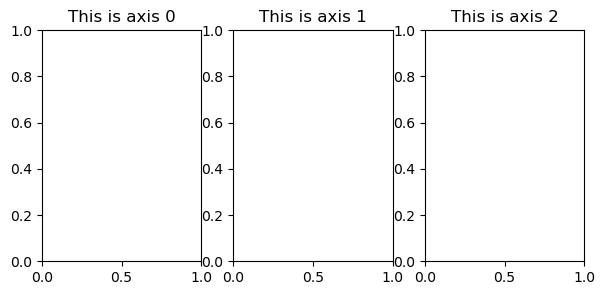

In [11]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(7, 3))

axes[0].set_title('This is axis 0')
axes[1].set_title('This is axis 1')
axes[2].set_title('This is axis 2')

plt.show()

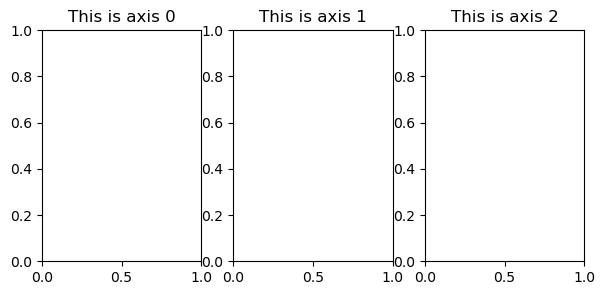

In [ ]:
## Basic for loop

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(7, 3))

for i in range(0,3): 
    axes[i].set_title(f'This is axis {i}')

plt.show()

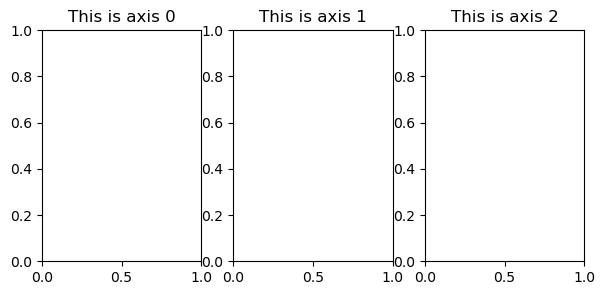

In [ ]:
## Using `zip()`

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(7, 3))

for ax, i in zip(axes, [0,1,2]):
    ax.set_title(f'This is axis {i}')

plt.show()

In this example, notice that the `axes` variable returned by the `plt.subplots()` function is actually an array of axes we can iterate over. Remember that the figure and the axes are separate elements in a matplotlib plot.

![alt text](https://meds-eds-220.github.io/MEDS-eds-220-course/book/images/lesson-10/matplotlib_figure_axes_axis.png)

### Check-in
Use for and zip() to create the same subplots and avoid redundancy.

1. Select the power plants in California in a variable named ca_power_plants.

2. Create a list named top_sources with California’s top 3 electric primary sources.

3. Isolate the California state boundary in a variable named ca_boundary.

4. Recreate the following plot:


In [16]:
# Filter power_plants by 'state' == CA
ca_power_plants = power_plants[power_plants['state'] == 'California']

# CA top 3 power sources were previously given
ca_top_sources = ['solar', 'natural gas', 'hydroelectric']

# Filter states by 'name' == CA
ca_boundary = states[states['name'] == 'California']


In [17]:
ca_power_plants.head()

,objectid,plant_code,plant_name,utility_id,utility_name,sector_name,street_address,city,county,state,zip,primsource,source_desc,tech_desc,install_mw,total_mw,bat_mw,bio_mw,coal_mw,geo_mw,hydro_mw,hydrops_mw,ng_mw,nuclear_mw,crude_mw,solar_mw,wind_mw,other_mw,source,period,longitude,latitude,geometry
421,62116,34,Rollins,13402,Nevada Irrigation District,IPP Non-CHP,15531 Arrow Head Lane,Colfax,Placer,California,95713,hydroelectric,Hydroelectric = 12.1 MW,Conventional Hydroelectric,12.1,12.1,0.0,0.0,0.0,0.0,12.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-120.953337,39.134255,POINT (-120.95334 39.13426)
443,62136,72,Venice Hydro,12397,Metropolitan Water District of S CA,Electric Utility,3815 Sepulveda Blvd,Culver City,Los Angeles,California,90230,hydroelectric,Hydroelectric = 10.1 MW,Conventional Hydroelectric,10.1,10.1,0.0,0.0,0.0,0.0,10.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-118.416798,34.011351,POINT (-118.41680 34.01135)
459,62152,104,J S Eastwood,17609,Southern California Edison Co,Electric Utility,Hwy 168 Sierra National Forest,Shaver Lake,Fresno,California,93664,pumped storage,Pumped Storage = 199.8 MW,Hydroelectric Pumped Storage,199.8,199.8,0.0,0.0,0.0,0.0,0.0,199.8,0.0,0.0,0.0,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-119.256698,37.147920,POINT (-119.25670 37.14792)
480,62172,151,McClure,12745,Modesto Irrigation District,Electric Utility,639 S. McClure Rd.,Modesto,Stanislaus,California,95354,natural gas,"Natural Gas = 53.5 MW, Petroleum = 53.5 MW",Natural Gas Fired Combustion Turbine; Petroleu...,142.4,107.0,0.0,0.0,0.0,0.0,0.0,0.0,53.5,0.0,53.5,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-120.931390,37.629358,POINT (-120.93139 37.62936)
486,62178,161,Turlock Lake,19281,Turlock Irrigation District,Electric Utility,21642 Davis Road,Hickman,Stanislaus,California,95323,hydroelectric,Hydroelectric = 3.3 MW,Conventional Hydroelectric,3.3,3.3,0.0,0.0,0.0,0.0,3.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-120.594677,37.611457,POINT (-120.59468 37.61146)


[]

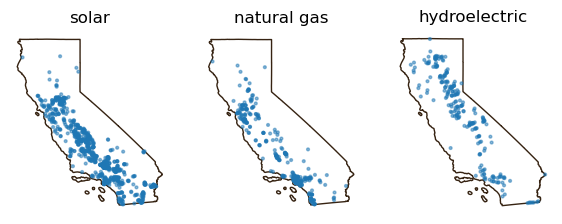

In [26]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(7, 3))

for ax, source in zip(axes, ca_top_sources):
    ax.set_title(source)
    ax.axis('off')
    ca_boundary.plot(
        ax=ax, 
        color='none', 
        edgecolor='#362312')
    subset = ca_power_plants[ca_power_plants['primsource'] == source]
    subset.plot(
        ax=ax, 
        column='primsource',
        markersize=4,
        cmap='tab20',
        alpha=0.5
        )

plt.plot()